## Qiskit Introdução

O Qiskit oferece uma estrutura para desenvolvimento e pesquisa de algoritmos quânticos, permitindo que pesquisadores projetem, testem e simulem circuitos quânticos.

- qiskit: desenvolvida e mantida pela IBM e open-source.
- qiskit_aer: também da IBM (era separado, hoje é parte do ecossistema Qiskit oficial).
- qiskit_ibm_runtime: da IBM, especificamente para acessar os QPUs reais na nuvem.

Todo o ecossistema Qiskit é ligado a IBM, Existem alternativas de outras empresas (Cirq do Google, PennyLane da Xanadu, Braket da Amazon).

## Computação quântica

A base da computação quântica é definida pelos vetores.

$$|0\rangle = \left[\begin{array}{c}1 \\0 \end{array}\right] ,\ |1\rangle = \left[\begin{array}{c}0 \\1 \end{array}\right] e\ X = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix}$$

### Porta NOT(X)

Representada pela letra X, ela inverte o estado quântico.

In [13]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import plot_histogram, plot_bloch_multivector, array_to_latex

import numpy as np
import sympy as sp
from IPython.display import display, Math

### Função estado atual

A função abaixo encontra o estado atual do qubit evitando o erro ao usar o Statevector, após o uso do `measure`. O Statevector pega todas as informações do circuito, e após fazermos o colapso, causa um erro, porque o measure não é uma porta unitária, é uma operação clássica, e o Statevector só sabe lidar com portas quânticas. 

In [2]:
def estado_atual(circuito):
    """Recalcula o Statevector atual do circuito, ignorando os measures já aplicados."""
    
    copia = QuantumCircuit(circuito.num_qubits)
    for instrucao in circuito.data:
        if instrucao.operation.name != "measure":
            copia.append(instrucao.operation, instrucao.qubits)
    return Statevector.from_instruction(copia)

In [3]:
def mostrar_equacao(circuito):
    
    quant_quantico = circuito.num_qubits
    quant_classico = circuito.num_clbits
    
    portas = []
    for instrucao in circuito.data:
        if instrucao.operation.name != "measure":
            portas.append(instrucao)
    
    def rotulo_ket(vetor):
        valores = list(vetor)
        if valores.count(1) == 1 and all(v in (0, 1) for v in valores):
            indice = valores.index(1)
            return "|" + format(indice, f"0{quant_quantico}b") + r"\rangle"
        return None

    estado = sp.Matrix([1] + [0] * (2**quant_quantico - 1))

    for instrucao in portas:
        circuito_porta = QuantumCircuit(quant_quantico, quant_classico)
        circuito_porta.append(instrucao.operation, instrucao.qubits)
        matriz = sp.Matrix(np.round(Operator(circuito_porta).data.real, 8)).applyfunc(
            lambda x: sp.nsimplify(x, [sp.sqrt(2)])
        )

        indices = ",".join(str(circuito.find_bit(q).index) for q in instrucao.qubits)
        nome_porta = r"\text{" + instrucao.operation.name.upper() + "}_{" + indices + "}"

        rotulo = rotulo_ket(estado)
        entrada_str = rotulo if rotulo is not None else sp.latex(estado)

        saida = matriz * estado

        expressao = (
            nome_porta + entrada_str + " = "
            + sp.latex(matriz) + sp.latex(estado)
            + " = " + sp.latex(saida)
        )
        display(Math(expressao))

        estado = saida

In [4]:
circuito = QuantumCircuit(1, 1)         # Determina o circuito e quantidade de qubits/bits.

estado_inicial = Statevector.from_instruction(circuito)
print("Estado inicial:")
display(estado_inicial.draw('latex'))

circuito.x(0);                          # Aplica a porta NOT, na posição (indice do qubit (0))

Estado inicial:


<IPython.core.display.Latex object>

In [5]:
matriz = Operator(circuito)             # Cria a matriz do circuito indicado.
display(array_to_latex(matriz.data, prefix="X = "))

<IPython.core.display.Latex object>

Neste caso da porta NOT(X) o estado é definido e não há superposição.

In [6]:
estado_final = estado_atual(circuito)    # Cria um vetor do circuito para ser plotado na esfera.
circuito.measure(0, 0);                 # Colapsa o estado quântico em um valor classico e grava no bit clássico (q, c). Aqui também são indices.

Contagens: {'1': 1}


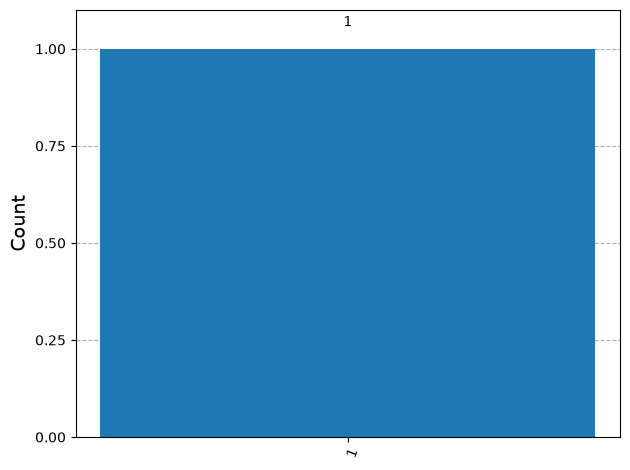

Estado final:


<IPython.core.display.Latex object>

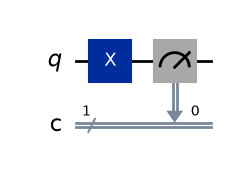

In [7]:
#Simulação
simulador = AerSimulator()
trabalho = simulador.run(circuito, shots=1)
resultado = trabalho.result()
contagens = resultado.get_counts()
print("Contagens:", contagens)
display(plot_histogram(contagens))

print("Estado final:")
display(estado_final.draw('latex'))
circuito.draw("mpl", style="iqp")

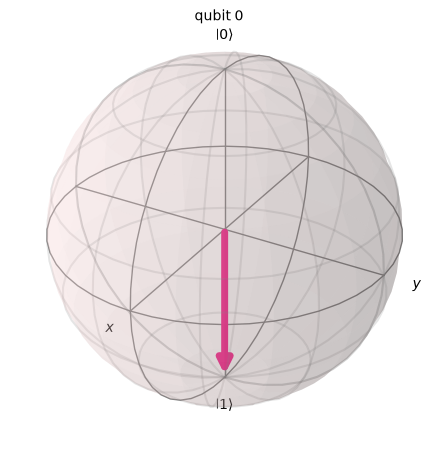

In [8]:
plot_bloch_multivector(estado_final)

In [9]:
circuito.x(0);  
estado_novo = estado_atual(circuito)
circuito.measure(0, 0);                 # Colapsa o estado quântico em um valor classico e grava no bit clássico (q, c). Aqui também são indices.
print("Estado depois do 2º NOT:")
display(estado_novo.draw('latex'))

Estado depois do 2º NOT:


<IPython.core.display.Latex object>

Contagens: {'0': 1}


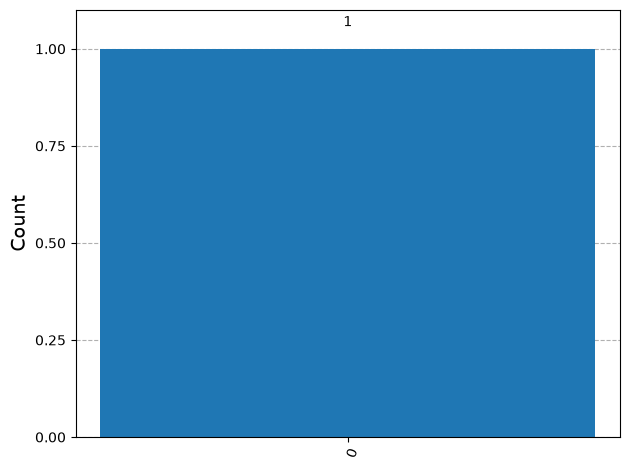

Contagens: {'0': 1}


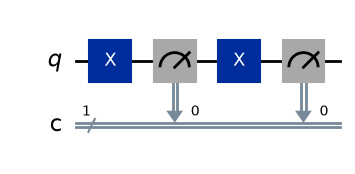

In [10]:
#Simulação
trabalho = simulador.run(circuito, shots=1)
resultado = trabalho.result()
contagens = resultado.get_counts()
print("Contagens:", contagens)
display(plot_histogram(contagens))

print("Contagens:", resultado.get_counts())   # {'0': 1}
circuito.draw("mpl", style="iqp")

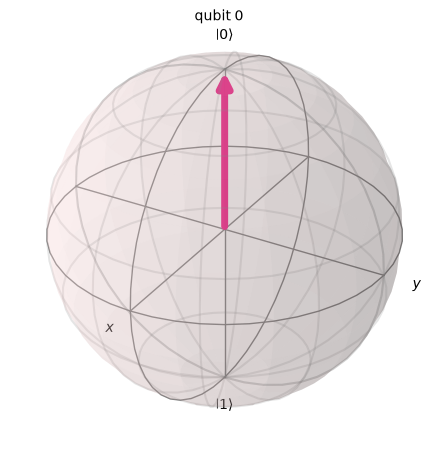

In [11]:
plot_bloch_multivector(estado_novo)

In [14]:
mostrar_equacao(circuito)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [20]:
circuito = QuantumCircuit(2, 2)
circuito.x(0)
circuito.x(1)
circuito.measure(0, 0)
circuito.measure(1, 1)
estado = estado_atual(circuito)

Contagens: {'11': 1}


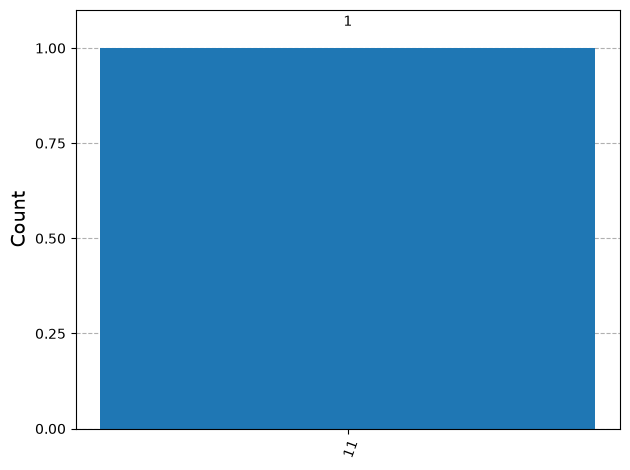

Contagens: {'11': 1}


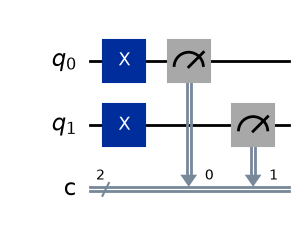

In [21]:
#Simulação
trabalho = simulador.run(circuito, shots=1)
resultado = trabalho.result()
contagens = resultado.get_counts()
print("Contagens:", contagens)
display(plot_histogram(contagens))

print("Contagens:", resultado.get_counts())   # {'0': 1}
circuito.draw("mpl", style="iqp")

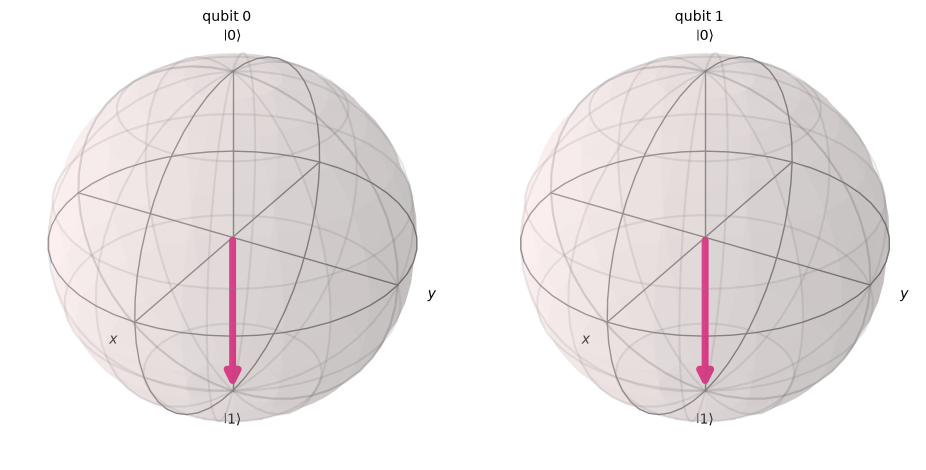

In [22]:
plot_bloch_multivector(estado)

In [23]:
mostrar_equacao(circuito)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [34]:
circuito2 = QuantumCircuit(2, 1)
circuito2.x(0)
circuito2.x(1)
circuito2.measure(0, 0)
circuito2.measure(1, 0)
estado_ = estado_atual(circuito2);

Contagens: {'1': 1}


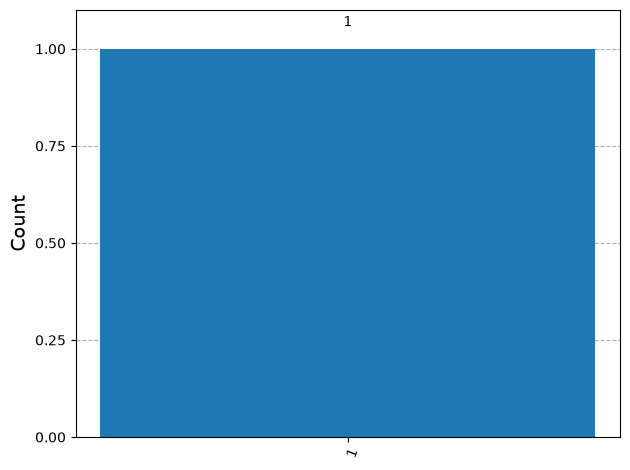

Contagens: {'1': 1}


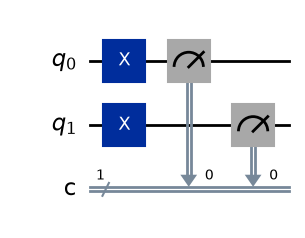

In [ ]:
#Simulação
trabalho2 = simulador.run(circuito2, shots=1)
resultado2 = trabalho2.result()
contagens2 = resultado2.get_counts()
print("Contagens:", contagens2)  
display(plot_histogram(contagens2))

print("Contagens:", resultado2.get_counts())   # {'0': 1}
circuito2.draw("mpl", style="iqp")

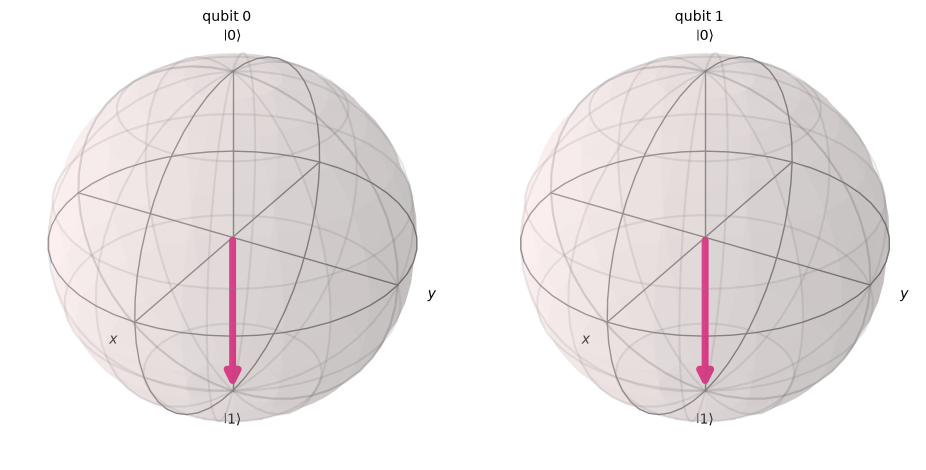

In [31]:
plot_bloch_multivector(estado_)

In [36]:
mostrar_equacao(circuito2)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [13]:
vetor_0 = np.array([[1],[0]])
display(array_to_latex(matriz.data, prefix="X="))
display(array_to_latex(vetor_0, prefix="|0\\rangle="))
display(array_to_latex(matriz.data @ vetor_0, prefix="X|0\\rangle="))

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

In [14]:
# ==========================================
# Quantum Entanglement Example - Local PC
# ==========================================

# Import Qiskit libraries
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# ------------------------------------------
# Create quantum and classical registers
# ------------------------------------------
qr = QuantumRegister(2, 'q')
cr = ClassicalRegister(2, 'c')

# Create the quantum circuit
circuit = QuantumCircuit(qr, cr)

# ------------------------------------------
# Create superposition with Hadamard gate
# ------------------------------------------
circuit.h(qr[0])

# ------------------------------------------
# Create entanglement with CNOT gate
# Control qubit = q0
# Target qubit  = q1
# ------------------------------------------
circuit.cx(qr[0], qr[1])

# ------------------------------------------
# Measure qubits
# ------------------------------------------
circuit.measure(qr, cr)

# ------------------------------------------
# Draw the circuit
# ------------------------------------------
print(circuit.draw())

# Optional graphical drawing
circuit.draw('mpl')
plt.show()

# ------------------------------------------
# Local simulation using AerSimulator
# ------------------------------------------
simulator = AerSimulator()

# Compile/transpile the circuit
compiled_circuit = transpile(circuit, simulator)

# Run the simulation
job = simulator.run(compiled_circuit, shots=1024)

# Get results
result = job.result()

# Get measurement counts
counts = result.get_counts()

# Print counts
print("\nMeasurement Results:")
print(counts)

# ------------------------------------------
# Plot histogram
# ------------------------------------------
plot_histogram(counts, title='Bell State Entanglement')
plt.show()

     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 

Measurement Results:
{'11': 529, '00': 495}


Resultados após 1000 execuções: {'0': 510, '1': 490}


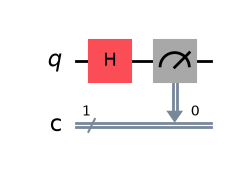

In [37]:
circuito = QuantumCircuit(1, 1)
circuito.h(0)

esfera_bloch = Statevector(circuito)
circuito.measure(0, 0)

#Simulação
simulador = AerSimulator()
trabalho = simulador.run(circuito, shots=1000)
resultado = trabalho.result()
contagem = resultado.get_counts()
print("Resultados após 1000 execuções:", contagem)


circuito.draw("mpl", style="iqp")

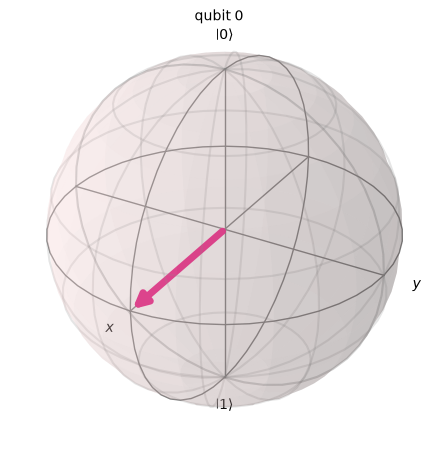

In [38]:
display(plot_bloch_multivector(esfera_bloch))

In [39]:
mostrar_equacao(circuito)

<IPython.core.display.Math object>

In [1]:
mostrar_equacao(circuit)

NameError: name 'mostrar_equacao' is not defined